# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3383 Панкратов Л. О. Вариант №17.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Импульсная характеристика $h[n]$ - отклик системы на единичный отсчет $\delta[n]$. При нулевых начальных условиях отклик причинной линейной стационарной системы равен свертке $y[n]=\sum_{m=0}^n h[m]x[n-m]$. Нули и полюсы - корни числителя и знаменателя передаточной функции $H(z)$. На единичной окружности $|H(e^{j\hat{\omega}})|$ задает АЧХ, а $\arg H(e^{j\hat{\omega}})$ - ФЧХ.

При $a_0=1$ звено второго порядка задается разностным уравнением

$$
y[n]=\sum_{m=0}^{2} b_m x[n-m]-\sum_{m=1}^{2} a_m y[n-m].
$$

Прямое и обратное ДПФ связывают $N$ отсчетов сигнала с комплексными коэффициентами спектра:

$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.
$$

Коэффициенты ряда Фурье периодического продолжения равны $C_k=X[k]/N$.

## Постановка задачи

1. Реализовать дискретную систему варианта 17. Вычислить импульсную характеристику и отклик на прямоугольный импульс, определить нули, полюсы, устойчивость, АЧХ и ФЧХ.
2. Исследовать с помощью ДПФ сумму двух гармоник. Сравнить спектры конечной и периодической последовательностей, восстановить аналоговый сигнал, проверить равенство Парсеваля и объяснить результаты.

## Выполнение работы

Расчеты выполнены на Python с библиотеками NumPy и Matplotlib.

### Часть 1. Линейная дискретная система

In [1]:
import numpy as np
import matplotlib.pyplot as plt

V = 17
b0 = 0.5 + 0.02 * V
# коэффициенты идут от нулевой задержки к задержке на два отсчета
b = np.array([
    b0,
    b0 * (-1) ** (V + 1) * (0.9822 + 0.0178 * V),
    b0 * (0.8 + 0.2 * (V % 5)),
])
a = np.array([1.0, (-1) ** V * (0.7778 + 0.025 * V), 0.64 + 0.006 * V])
N1 = 20 + V % 10
N2 = 30 + V % 10
fs1 = 1000 * V
print("b =", np.round(b, 6))
print("a =", np.round(a, 6))
print(f"N1 = {N1}, N2 = {N2}, частота дискретизации = {fs1} Гц")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.unicode_minus": False,
})


def stem(ax, coords, values, title, xlabel, ylabel):
    ax.axhline(0, color="0.7", linewidth=0.7)
    ax.vlines(coords, 0, values, color="C0", linewidth=1)
    ax.plot(coords, values, "o", color="C0", markersize=3)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

b = [0.84     1.079232 1.008   ]
a = [ 1.     -1.2028  0.742 ]
N1 = 27, N2 = 37, частота дискретизации = 17000 Гц


#### 1.1. Импульсная характеристика

Для единичного импульса и нулевых начальных условий первые отсчеты равны $h[0]=b_0=0.84$, $h[1]=b_1-a_1h[0]=2.089584$ и $h[2]=b_2-a_1h[1]-a_2h[0]=2.8980716352$. При $n\ge3$ все входные слагаемые равны нулю. Корни уравнения $p^2-1.2028p+0.742=0$ имеют вид $r e^{\pm j\theta}$. Радиус $r=\sqrt{0.742}$ задает затухание, угол $\theta=\arccos(1.2028/(2r))$ - частоту колебаний.

При $k=n-1$ аналитическая формула имеет вид

$$
h[n]=\begin{cases}
0,&n<0,\\
0.84,&n=0,\\
r^k\big(C\cos(k\theta)+D\sin(k\theta)\big),&n\ge1.
\end{cases}
$$

Подстановка $n=1$ и $n=2$ дает $C=h[1]=2.089584$ и $D=(h[2]/r-C\cos\theta)/\sin\theta\approx2.66158205$.

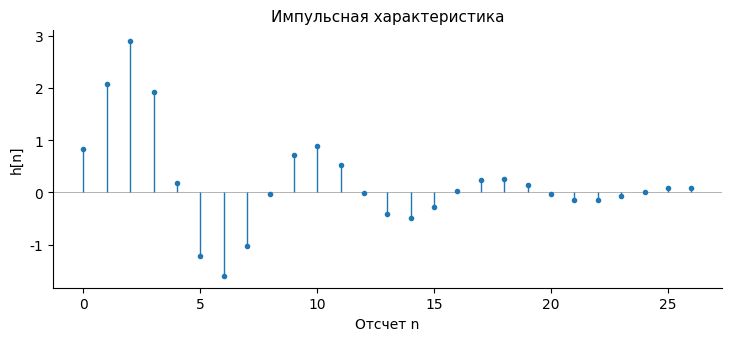

In [2]:
def response(x, b, a):
    y = np.zeros(len(x))
    for n in range(len(x)):
        y[n] = b[0] * x[n]
        # до начала сигнала вход и выход нулевые
        if n >= 1:
            y[n] += b[1] * x[n - 1] - a[1] * y[n - 1]
        if n >= 2:
            y[n] += b[2] * x[n - 2] - a[2] * y[n - 2]
    return y


# отклик на единичный импульс дает первые N1 отсчетов характеристики
delta = np.zeros(N1)
delta[0] = 1
h = response(delta, b, a)

fig, ax = plt.subplots(figsize=(7.2, 3.3), constrained_layout=True)
stem(ax, np.arange(N1), h, "Импульсная характеристика", "Отсчет n", "h[n]")
plt.show()

На графике показаны первые 27 отсчетов. Истинная характеристика бесконечна. Множитель $r^k$ при $r\approx0.8614$ задает затухание колебаний.

#### 1.2. Реакция по формуле свертки

При округлении $37/2=18.5$ вверх получаются 19 единичных отсчетов ($n=0,\ldots,18$). Остальные 18 отсчетов входа равны нулю.

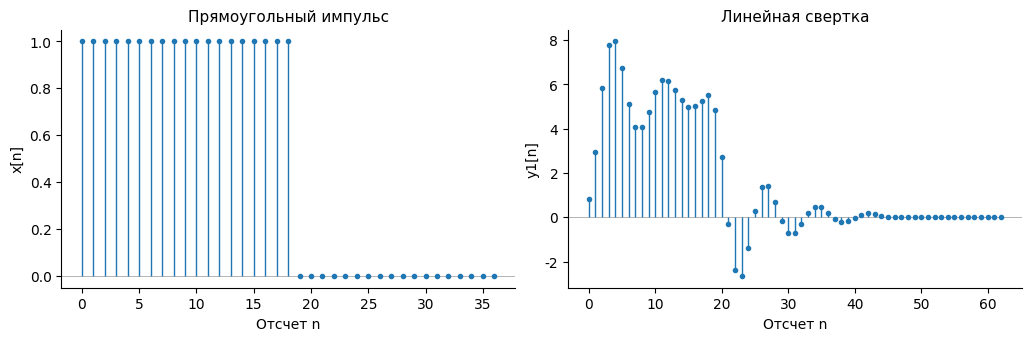

In [3]:
n_in = np.arange(N2)
# половина от 37 равна 18.5, округление вверх дает 19 единиц
width = int(np.floor(N2 / 2 + 0.5))
x_rect = (n_in < width).astype(float)
y1_full = np.zeros(N1 + N2 - 1)
for i, value in enumerate(x_rect):
    # вклад каждого входного отсчета начинается с его номера i
    y1_full[i:i + N1] += value * h
y1 = y1_full[:N2]

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.3), constrained_layout=True)
stem(axes[0], n_in, x_rect, "Прямоугольный импульс", "Отсчет n", "x[n]")
stem(axes[1], np.arange(len(y1_full)), y1_full, "Линейная свертка", "Отсчет n", "y1[n]")
plt.show()

Для массивов длиной 37 и 27 свертка содержит $37+27-1=63$ отсчета ($n=0,\ldots,62$ на графике). В вычисленной свертке отсчеты с $n=45$ по $n=62$ нулевые, поскольку входной импульс заканчивается на $n=18$, а фрагмент $h[n]$ - на $n=26$. Для сравнения с реакцией на интервале входной записи берутся первые 37 отсчетов свертки.

#### 1.3. Реакция по разностному уравнению

$$
y_2[n]=0.84x[n]+1.079232x[n-1]+1.008x[n-2]+1.2028y_2[n-1]-0.742y_2[n-2].
$$

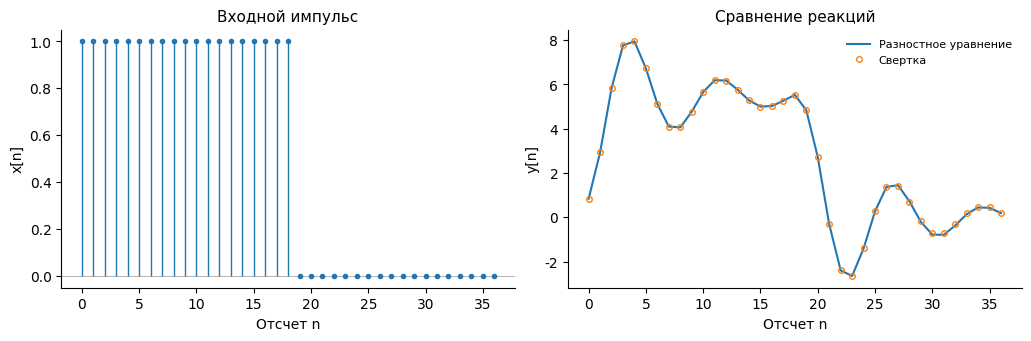

Максимальная разность: 0.081776 при n = 31


In [4]:
y2 = response(x_rect, b, a)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.3), constrained_layout=True)
stem(axes[0], n_in, x_rect, "Входной импульс", "Отсчет n", "x[n]")
axes[1].plot(n_in, y2, color="C0", label="Разностное уравнение")
axes[1].plot(n_in, y1, "o", color="C1", fillstyle="none", markersize=4, label="Свертка")
axes[1].set(title="Сравнение реакций", xlabel="Отсчет n", ylabel="y[n]")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
plt.show()
difference = np.abs(y2 - y1)
i_diff = np.argmax(difference)
print(f"Максимальная разность: {difference[i_diff]:.6f} при n = {n_in[i_diff]}")

Вход и рассчитанный по уравнению выход имеют длину 37. До $n=26$ реакции совпадают с точностью округления. При $n=27$ в полной свертке впервые появляется слагаемое $h[27]x[0]$. В сохраненных 27 отсчетах последнее значение - $h[26]$, поэтому с этого момента результаты расходятся. Максимальная разность по модулю равна 0,081776 при $n=31$.

#### 1.4. Нули и полюсы

Для $H(z)=(0.84z^2+1.079232z+1.008)/(z^2-1.2028z+0.742)$ каждый корень можно записать как $s=u+jv=\rho e^{j\varphi}$, где $\rho=\sqrt{u^2+v^2}$, $\varphi=\operatorname{atan2}(v,u)$. Сопряженные корни имеют равные модули и противоположные аргументы.

In [5]:
# numpy.roots принимает коэффициенты начиная со старшей степени
zeros = np.roots(b)
poles = np.roots(a)
print(f"{'Тип':<8}{'Алгебраическая форма':<26}Показательная форма")
for kind, roots in (("Нуль", zeros), ("Полюс", poles)):
    for z in roots:
        alg = f"{z.real:.6f} {z.imag:+.6f}j"
        polar = f"{abs(z):.6f} exp({np.angle(z) / np.pi:+.6f} πj)"
        print(f"{kind:<8}{alg:<26}{polar}")

Тип     Алгебраическая форма      Показательная форма
Нуль    -0.642400 +0.887312j      1.095445 exp(+0.699466 πj)
Нуль    -0.642400 -0.887312j      1.095445 exp(-0.699466 πj)
Полюс   0.601400 +0.616699j       0.861394 exp(+0.253998 πj)
Полюс   0.601400 -0.616699j       0.861394 exp(-0.253998 πj)


С подстановкой показательной формы корней передаточная функция равна приближенно

$$
H(z)\approx0.84\prod_{\sigma\in\{-1,1\}}
\frac{1-1.095445\,e^{j\sigma\,0.699466\pi}z^{-1}}
     {1-0.861394\,e^{j\sigma\,0.253998\pi}z^{-1}}.
$$

#### 1.5. Карта нулей и полюсов

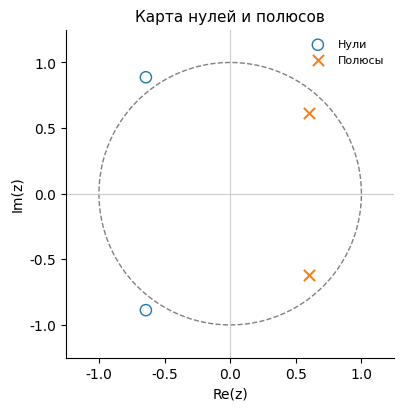

In [6]:
angle = np.linspace(0, 2 * np.pi, 361)
fig, ax = plt.subplots(figsize=(5.2, 4.0), constrained_layout=True)
# пунктир показывает единичную окружность
ax.plot(np.cos(angle), np.sin(angle), "--", color="0.5", linewidth=1)
ax.axhline(0, color="0.8", linewidth=0.8)
ax.axvline(0, color="0.8", linewidth=0.8)
ax.scatter(zeros.real, zeros.imag, s=65, facecolors="none", edgecolors="C0", label="Нули")
ax.scatter(poles.real, poles.imag, s=65, marker="x", color="C1", label="Полюсы")
ax.set(aspect="equal", xlim=(-1.25, 1.25), ylim=(-1.25, 1.25),
       title="Карта нулей и полюсов", xlabel="Re(z)", ylabel="Im(z)")
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.show()

Кружки обозначают нули, кресты - полюсы. Координаты совпадают с таблицей п. 1.4. Оба полюса лежат внутри единичной окружности ($|p|\approx0.8614<1$), поэтому звено устойчиво.

#### 1.6. АЧХ и ФЧХ в нормированной шкале

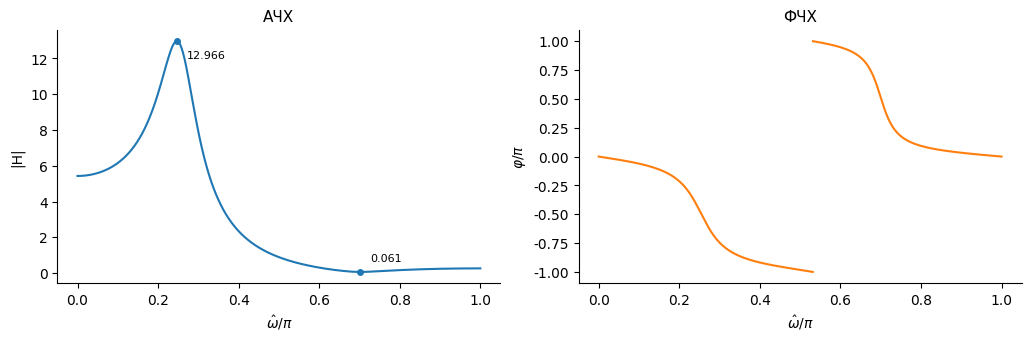

In [7]:
w = np.linspace(0, np.pi, 4097)
# на единичной окружности q соответствует задержке на один отсчет
q = np.exp(-1j * w)
H = (b[0] + b[1] * q + b[2] * q**2) / (a[0] + a[1] * q + a[2] * q**2)
gain = np.abs(H)
phase = np.angle(H)
# пропуск между ветвями фазы убирает вертикальную линию на графике
phase_plot = phase.copy()
phase_plot[np.flatnonzero(np.abs(np.diff(phase)) > np.pi) + 1] = np.nan


def plot_response(frequency, xlabel):
    fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.3), constrained_layout=True)
    axes[0].plot(frequency, gain, color="C0")
    # подписи отмечают вершину резонанса и дно провала
    for i, offset in ((np.argmax(gain), -12), (np.argmin(gain), 8)):
        axes[0].plot(frequency[i], gain[i], "o", color="C0", markersize=4)
        axes[0].annotate(f"{gain[i]:.3f}", (frequency[i], gain[i]),
                         xytext=(7, offset), textcoords="offset points", fontsize=8)
    axes[0].set(title="АЧХ", xlabel=xlabel, ylabel="|H|")
    axes[1].plot(frequency, phase_plot / np.pi, color="C1")
    axes[1].set(title="ФЧХ", xlabel=xlabel, ylabel=r"$\varphi/\pi$")
    plt.show()


plot_response(w / np.pi, r"$\hat{\omega}/\pi$")

Основная неотрицательная полоса - $0\le\hat{\omega}\le\pi$ (полный период - $[-\pi,\pi)$). Когда точка $e^{j\hat{\omega}}$ проходит близко к полюсу, модуль знаменателя уменьшается. Поэтому вблизи угла полюса $0.254\pi$ возникает пик АЧХ с усилением 12,97 при $0.247\pi$. Вблизи угла нуля $0.699\pi$ уменьшается модуль числителя, и АЧХ опускается до 0,061. У постоянной составляющей усиление равно 5,429, у частоты Найквиста - 0,261. В реакции преимущественно подавлена высокочастотная часть входа.

Нулей на единичной окружности нет. Скачка фазы на $\pi$ при нулевой АЧХ не возникает. Разрыв около $0.532\pi$ - переход главного значения фазы от $-\pi$ к $+\pi$ при $|H|\approx0.651$.

#### 1.7. АЧХ и ФЧХ в герцах

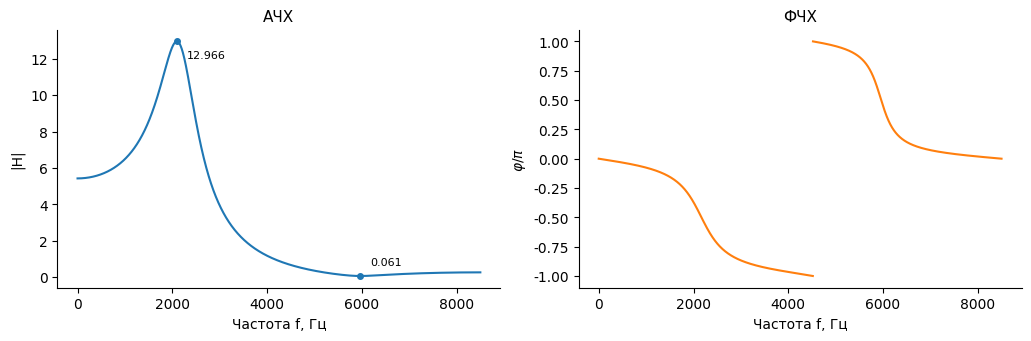

In [8]:
# при w = pi правая граница шкалы равна fs1/2
plot_response(w * fs1 / (2 * np.pi), "Частота f, Гц")

При $f_s=17\,000$ Гц основной неотрицательной полосе соответствуют частоты от 0 до 8500 Гц. Двусторонняя основная полоса занимает $[-8500,8500)$ Гц. Связь шкал дается формулой $f=\hat{\omega} f_s/(2\pi)$. На графике пик находится вблизи 2,10 кГц, минимум - вблизи 5,97 кГц.

### Часть 2. Дискретное преобразование Фурье

#### 2.1. Последовательность в двух шкалах времени

Для варианта 17 частота дискретизации равна 6000 Гц, период дискретизации $T=1/6000$ с. На интервале из $N=64$ отсчетов задана сумма гармоник

$$
x[n]=1.17\cos(2\pi\cdot750nT+\pi/4)+2.34\cos(2\pi\cdot1125nT+\pi/8).
$$

Дискретное время $t_n=nT$ измеряется в секундах. Нормированное время $t_n/T=n$ равно номеру отсчета. За время $NT$ первая гармоника совершает 8 полных колебаний, вторая - 12. Наименьший общий период равен 16 отсчетам, поэтому в блоке длиной 64 форма сигнала повторяется четыре раза.

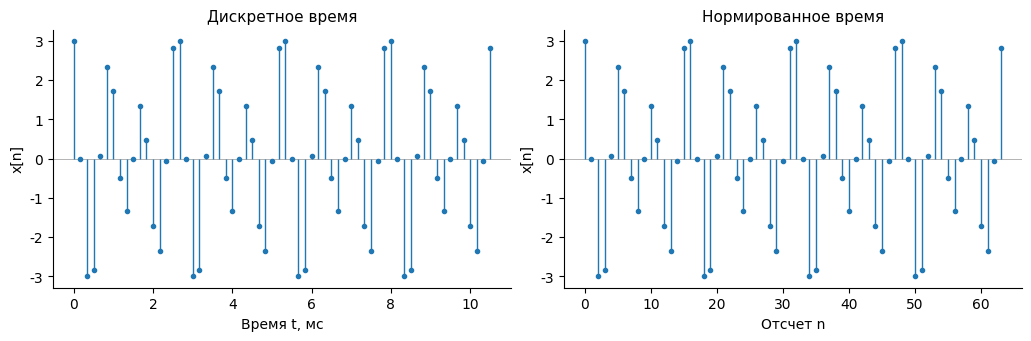

In [9]:
N = 64
fs2 = 2000 * (V % 5 + 1)
T = 1 / fs2
A1 = 1 + 0.01 * V
A2 = 2 * A1
f1 = fs2 / 8
f2 = 1.5 * f1


def signal(t):
    return (A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4)
            + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8))


n = np.arange(N)
# для косинусов время нужно в секундах, для графика - в миллисекундах
t_n = n * T
x = signal(t_n)
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.3), constrained_layout=True)
stem(axes[0], 1000 * t_n, x, "Дискретное время", "Время t, мс", "x[n]")
stem(axes[1], n, x, "Нормированное время", "Отсчет n", "x[n]")
plt.show()

#### 2.2. Обратное ДПФ

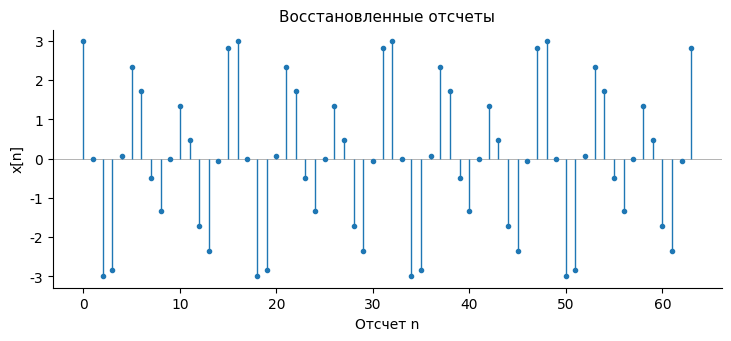

Максимальная ошибка ОДПФ: 8.88e-16


In [10]:
X = np.fft.fft(x)
# в numpy обратное преобразование уже включает деление на N
x_back = np.fft.ifft(X).real
fig, ax = plt.subplots(figsize=(7.2, 3.3), constrained_layout=True)
stem(ax, n, x_back, "Восстановленные отсчеты", "Отсчет n", "x[n]")
plt.show()
print(f"Максимальная ошибка ОДПФ: {np.max(np.abs(x_back - x)):.2e}")

Обратное ДПФ воспроизводит все 64 исходных отсчета с ошибкой менее $10^{-12}$.

#### 2.3. Амплитудный и фазовый спектры

Для линии $k$ нормированная частота равна $\nu_k=k/N$ циклов на отсчет, абсолютная - $f_k=\nu_k f_s$ в герцах. Угловая частота в обозначениях части 1 равна $\hat{\omega}_k=2\pi\nu_k$ рад/отсчет. Шаг по частоте составляет $f_s/N=93.75$ Гц.

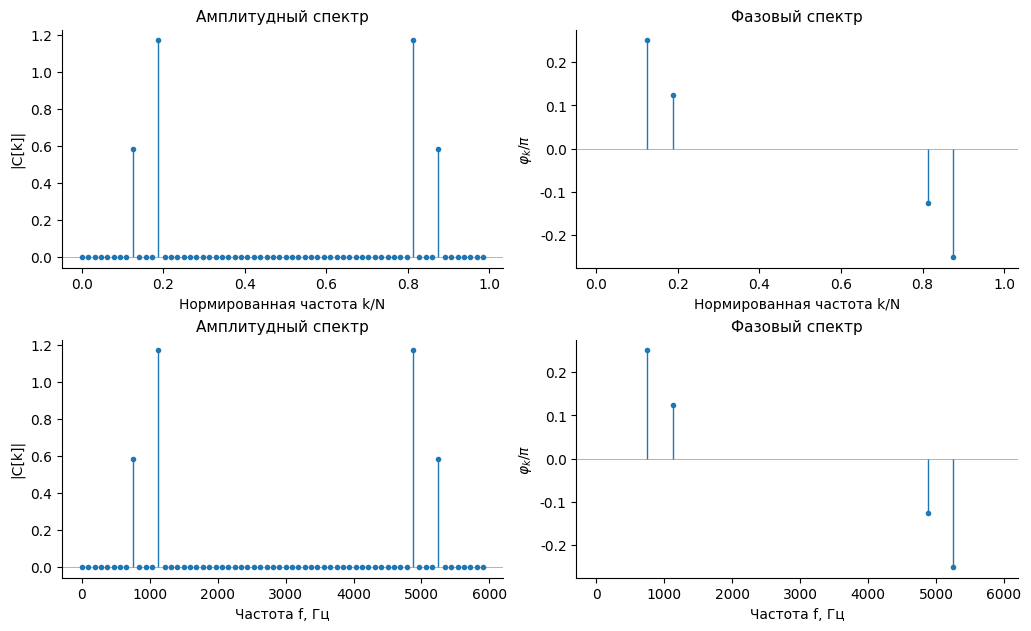

In [11]:
k = np.arange(N)
df = fs2 / N
Ck = X / N
amp = np.abs(Ck)
phi = np.angle(Ck) / np.pi
# для теоретически нулевых линий фаза определяется только шумом округления
active = amp > 1e-10 * amp.max()

fig, axes = plt.subplots(2, 2, sharex="row", figsize=(10.2, 6.2), constrained_layout=True)
for row, freq, label in ((0, k / N, "Нормированная частота k/N"), (1, k * df, "Частота f, Гц")):
    stem(axes[row, 0], freq, amp, "Амплитудный спектр", label, "|C[k]|")
    stem(axes[row, 1], freq[active], phi[active], "Фазовый спектр", label, r"$\varphi_k/\pi$")
plt.show()

Гармоники попадают в узлы $k=8$ (750 Гц) и $k=12$ (1125 Гц). Каждый косинус амплитуды $A$ дает две комплексные линии с модулями $A/2$ на частотах $+f$ и $-f$. Поэтому у положительных линий амплитуды равны 0,585 и 1,17, а фазы - $\pi/4$ и $\pi/8$. Сопряженные линии $k=56$ и $k=52$ соответствуют -750 и -1125 Гц и имеют противоположные фазы.

#### 2.4. ДПФ конечной записи и спектр периодической последовательности

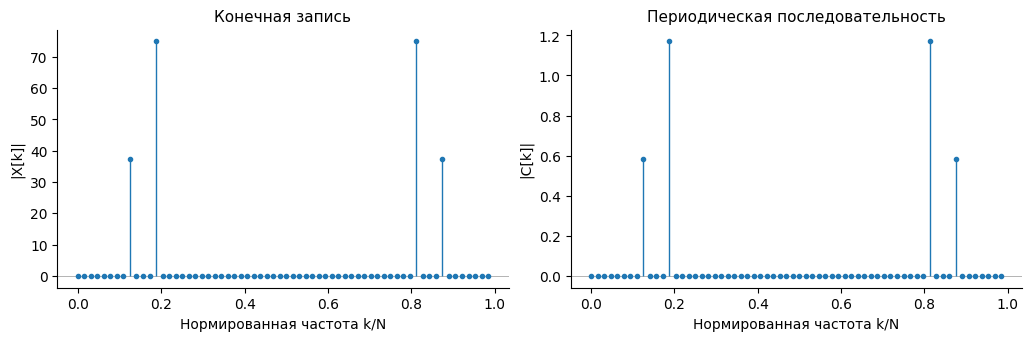

In [12]:
# для конечного блока спектр рассчитывается по сумме из определения ДПФ
X_finite = np.exp(-2j * np.pi * np.outer(k, n) / N) @ x
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(10.2, 3.3), constrained_layout=True)
stem(axes[0], k / N, np.abs(X_finite), "Конечная запись", "Нормированная частота k/N", "|X[k]|")
stem(axes[1], k / N, amp, "Периодическая последовательность", "Нормированная частота k/N", "|C[k]|")
plt.show()

Сравнение выполнено в одних и тех же узлах частотной сетки ДПФ. Модуль ДПФ конечной записи в $N=64$ раза больше двусторонней амплитуды периодического сигнала. Значениям 37,44 и 74,88 соответствуют 0,585 и 1,17.

#### 2.5. Восстановление аналогового сигнала

Для знаковых индексов $k=-32,\ldots,31$ коэффициенты берутся как $X_a[k]=X[k\bmod N]$. Восстановление выполняется на интервале $0\le t\le63T$ с шагом $T/4$. На этой сетке $4(N-1)+1=253$ точки. Значения между исходными отсчетами дает сумма

$$
x_{\mathrm{rec}}(t)=\frac{1}{N}\sum_{k=-32}^{31}X_a[k]\exp\!\left(j2\pi\frac{k}{NT}t\right).
$$

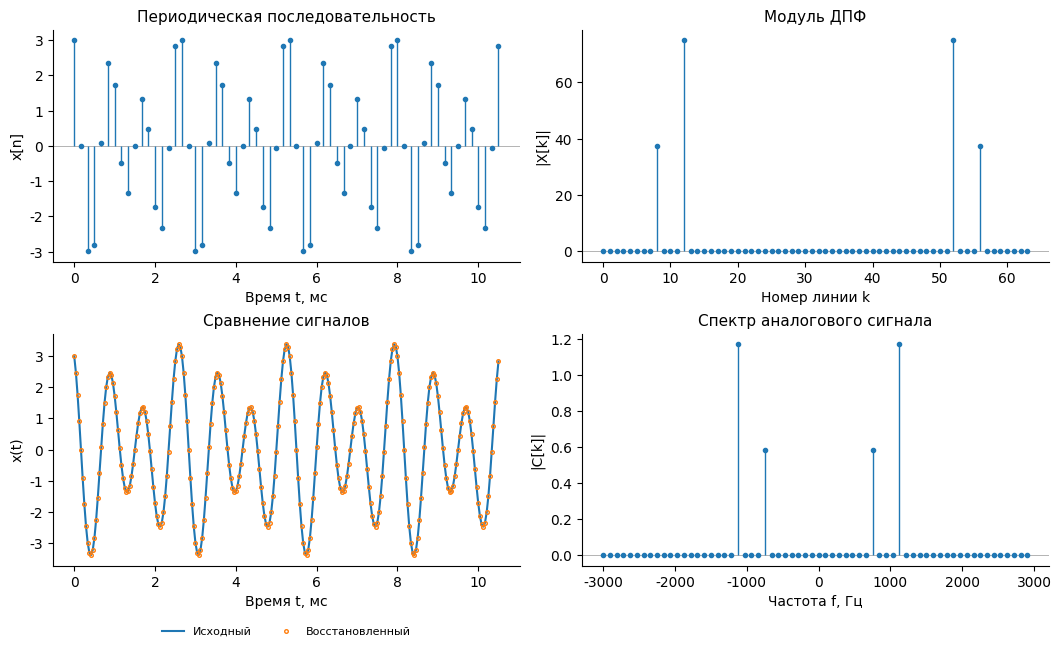

Максимальная ошибка на сетке T/4: 3.69e-14


In [13]:
k_signed = np.arange(-(N // 2), N // 2)
# например, k = -8 соответствует коэффициенту X[56]
Xa = X[k_signed % N]
f_signed = k_signed * df
t_fine = np.arange(4 * (N - 1) + 1) * T / 4
# каждая строка содержит значения комплексных экспонент в один момент времени
basis = np.exp(2j * np.pi * np.outer(t_fine, f_signed))
x_rec = (basis @ Xa / N).real
x_ref = signal(t_fine)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), constrained_layout=True)
stem(axes[0, 0], 1000 * t_n, x, "Периодическая последовательность", "Время t, мс", "x[n]")
stem(axes[0, 1], k, np.abs(X), "Модуль ДПФ", "Номер линии k", "|X[k]|")
axes[1, 0].plot(1000 * t_fine, x_ref, color="C0", label="Исходный")
axes[1, 0].plot(1000 * t_fine, x_rec, "o", markersize=2.6, fillstyle="none", color="C1",
                label="Восстановленный")
axes[1, 0].set(title="Сравнение сигналов", xlabel="Время t, мс", ylabel="x(t)")
axes[1, 0].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
stem(axes[1, 1], f_signed, np.abs(Xa) / N, "Спектр аналогового сигнала", "Частота f, Гц", "|C[k]|")
plt.show()
print(f"Максимальная ошибка на сетке T/4: {np.max(np.abs(x_rec - x_ref)):.2e}")

#### 2.6. Сравнение сигналов и спектров

Деление модуля ДПФ на 64 дает высоты линий аналогового спектра на частотах $\pm750$ и $\pm1125$ Гц. На совмещенном графике восстановленные точки лежат на исходной кривой и между отсчетами $nT$. Обе частоты ниже частоты Найквиста 3000 Гц, а интервал $NT$ содержит целое число периодов каждой гармоники.

#### 2.7. Проверка равенства Парсеваля

In [14]:
E_time = np.sum(x**2)
# для ненормированного прямого ДПФ спектральная сумма делится на N
E_freq = np.sum(np.abs(X)**2) / N
print(f"По отсчетам сигнала: {E_time:.6f}")
print(f"По коэффициентам ДПФ: {E_freq:.6f}")
print(f"Расхождение: {abs(E_time - E_freq):.2e}")

По отсчетам сигнала: 219.024000
По коэффициентам ДПФ: 219.024000
Расхождение: 2.84e-14


Равенство $\sum_{n=0}^{N-1}|x[n]|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X[k]|^2$ выполнено с точностью округления. Энергия одного блока одинакова во временном и частотном представлениях.

## Выводы

Оба полюса звена имеют модуль 0,8614, поэтому импульсная характеристика затухает и система устойчива. Свертка с первыми 27 отсчетами характеристики воспроизводит решение разностного уравнения до $n=26$ включительно. С $n=27$ сказывается отброшенный хвост. В пределах входной записи наибольшая разность равна 0,081776 при $n=31$.

Вблизи 2,10 кГц полюсы создают резонанс с усилением по амплитуде 12,97. Вблизи 5,97 кГц из-за близости нулей коэффициент передачи снижается до 0,0607. Эта высокочастотная составляющая ослабляется примерно в 16,5 раза, но полностью не исчезает.

В спектре второго сигнала частоты 750 и 1125 Гц совпали с узлами $k=8$ и $k=12$. Удвоение модулей положительных линий дает амплитуды исходных косинусов 1,17 и 2,34. На всех 253 точках сетки $T/4$, включая точки между исходными отсчетами, ошибка восстановления меньше $10^{-12}$. Энергия блока по времени и по спектру равна 219,024 с точностью округления, что подтверждает равенство Парсеваля.